In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [2]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [3]:
df['isBestSeller'] = df['isBestSeller'].astype(int)

In [4]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'])
crosstab.head()

isBestSeller,0,1
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


In [6]:
best_seller_prop = (
    crosstab[1] / (crosstab[0] + crosstab[1])
).sort_values(ascending=False)

best_seller_prop.head(10)

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Wind Instruments                  0.028000
Mirrors                           0.028000
dtype: float64

Some categories have a much higher proportion of best-selling products than others, suggesting that best-seller status is not evenly distributed across categories.

In [8]:
chi2, p_value, dof, expected = chi2_contingency(crosstab)

chi2, p_value


(36540.20270061387, 0.0)

In [10]:
import numpy as np

n = crosstab.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(crosstab.shape) - 1)))

cramers_v

0.1222829439760564

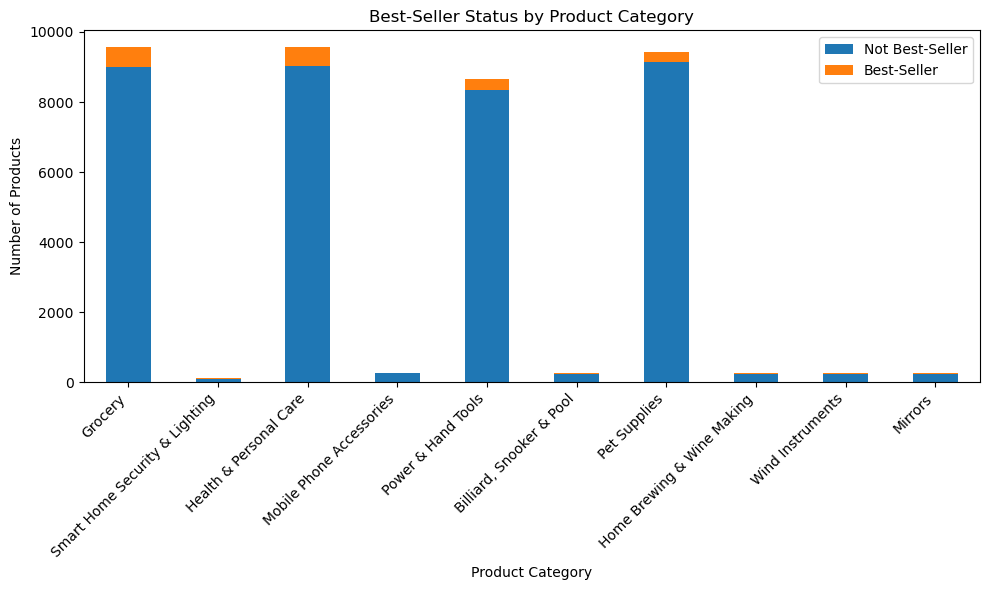

In [11]:
top_categories = best_seller_prop.head(10).index

crosstab.loc[top_categories].plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title("Best-Seller Status by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.legend(["Not Best-Seller", "Best-Seller"])
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [12]:
df['price'] = pd.to_numeric(df['price'], errors='coerce')


df_price = df[df['price'] > 0]


Q1 = df_price['price'].quantile(0.25)
Q3 = df_price['price'].quantile(0.75)
IQR = Q3 - Q1


lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


df_no_outliers = df_price[
    (df_price['price'] >= lower_bound) &
    (df_price['price'] <= upper_bound)
]

df_no_outliers.shape


(2115943, 9)

In [16]:
top_20_categories = (
    df_no_outliers['category']
    .value_counts()
    .head(20)
    .index
)

df_top20 = df_no_outliers[df_no_outliers['category'].isin(top_20_categories)]



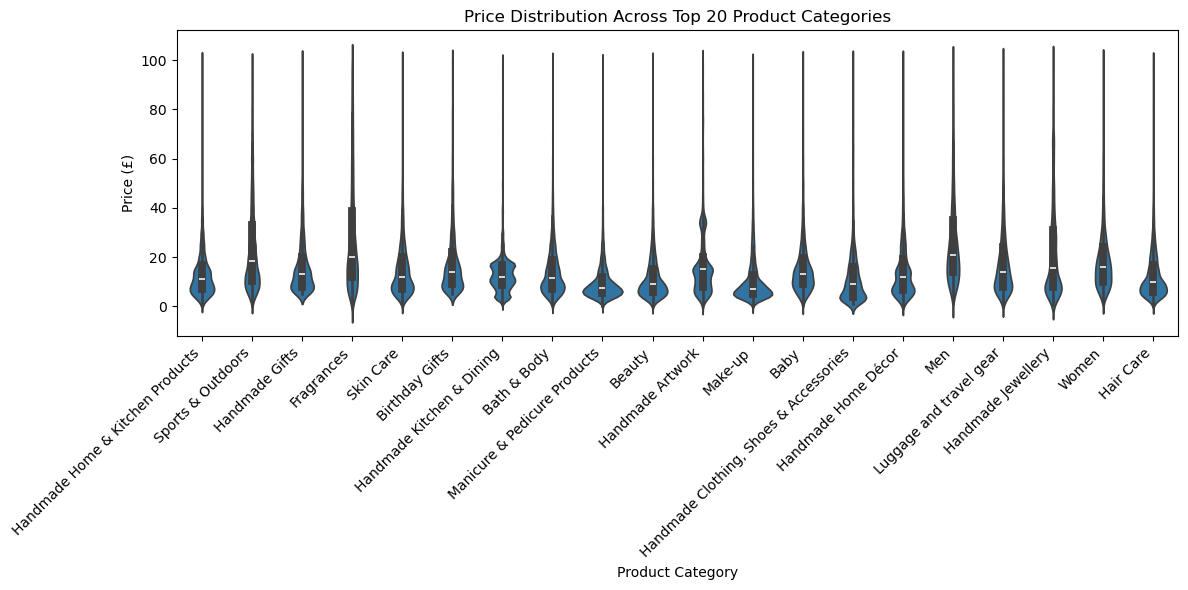

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.violinplot(
    data=df_top20,
    x='category',
    y='price'
)

plt.xticks(rotation=45, ha='right')
plt.title("Price Distribution Across Top 20 Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Price (£)")
plt.tight_layout()
plt.show()


Based on the violin plot, Handmade Jewellery appears to have the highest median price among the displayed product categories.

In [18]:
top_10_categories = (
    df_no_outliers['category']
    .value_counts()
    .head(10)
    .index
)

avg_price_by_category = (
    df_no_outliers[df_no_outliers['category'].isin(top_10_categories)]
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)


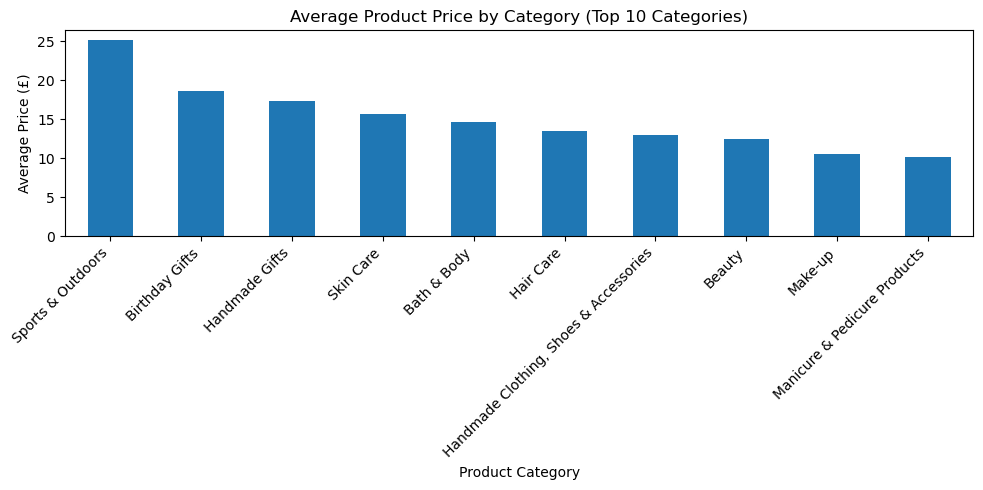

In [19]:
plt.figure(figsize=(10, 5))
avg_price_by_category.plot(kind='bar')
plt.title("Average Product Price by Category (Top 10 Categories)")
plt.xlabel("Product Category")
plt.ylabel("Average Price (£)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


Based on the bar chart, Sports and Outdoors appears to have the highest average price among the displayed product categories.

In [23]:
df['stars'] = pd.to_numeric(df['stars'], errors='coerce')

df_ratings = df[
    (df['stars'] >= 1) &
    (df['stars'] <= 5)
]


In [24]:
top_10_categories = (
    df_ratings['category']
    .value_counts()
    .head(10)
    .index
)

df_top10 = df_ratings[df_ratings['category'].isin(top_10_categories)]


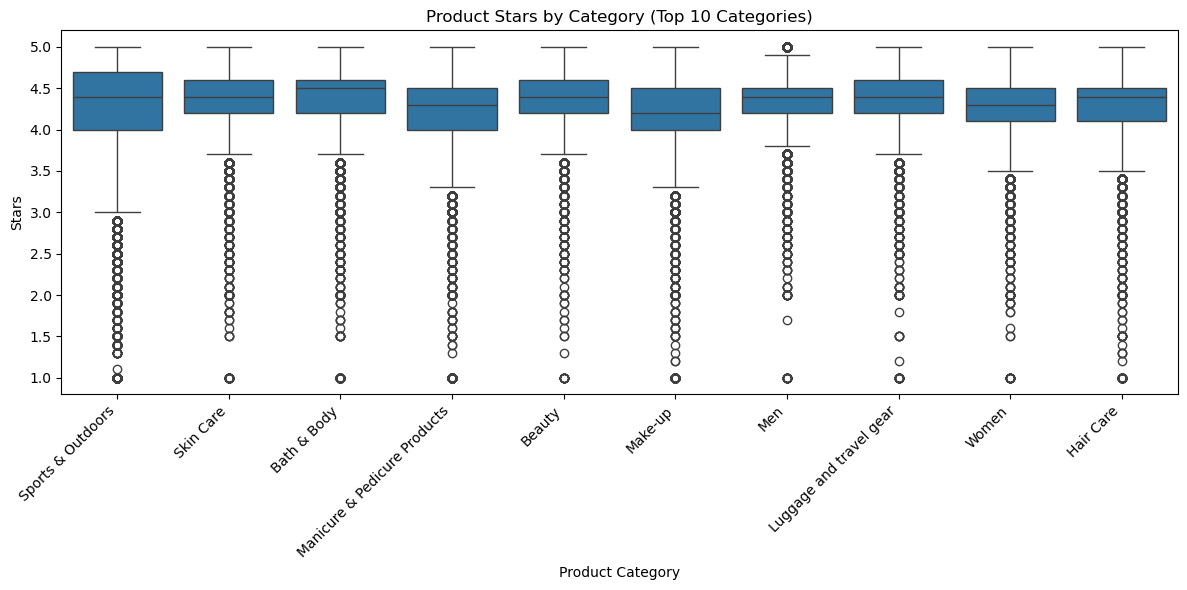

In [26]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_top10,
    x='category',
    y='stars'
)

plt.xticks(rotation=45, ha='right')
plt.title("Product Stars by Category (Top 10 Categories)")
plt.xlabel("Product Category")
plt.ylabel("Stars")
plt.tight_layout()
plt.show()


Based on the box chart, Bath and body appears to have the highest median customer rating among the categories shown.

In [27]:
correlation = df_no_outliers[['price', 'stars']].corr()
correlation


,price,stars
price,1.000000,-0.077663
stars,-0.077663,1.000000


The correlation between product price and rating is weak, meaning higher-priced products do not necessarily receive higher ratings.

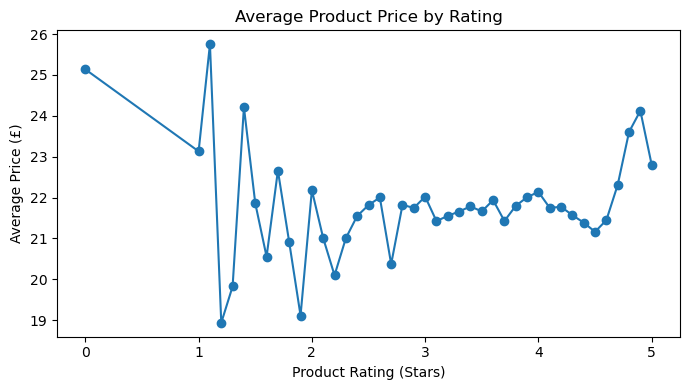

In [29]:
avg_price_by_rating = (
    df_no_outliers
    .groupby('stars')['price']
    .mean()
)

plt.figure(figsize=(7, 4))
plt.plot(
    avg_price_by_rating.index,
    avg_price_by_rating.values,
    marker='o'
)

plt.title("Average Product Price by Rating")
plt.xlabel("Product Rating (Stars)")
plt.ylabel("Average Price (£)")
plt.tight_layout()
plt.show()


The scatter plot shows no clear relationship between product price and rating, as prices vary widely across all rating levels.

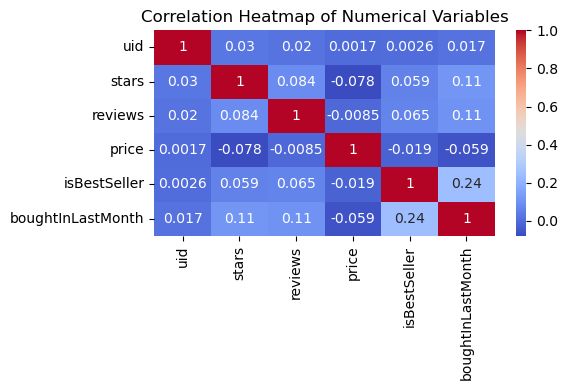

In [32]:
plt.figure(figsize=(6, 4))
sns.heatmap(
    df_no_outliers.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()


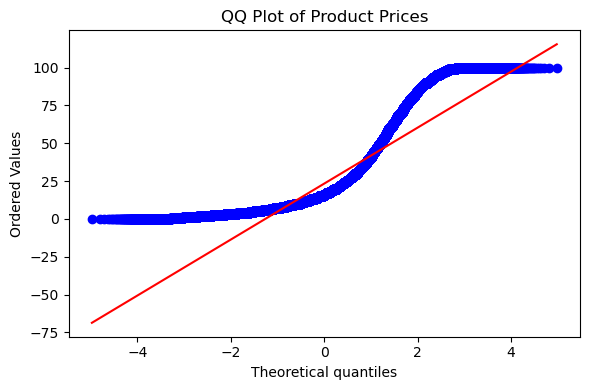

In [35]:
import scipy.stats as stats

plt.figure(figsize=(6, 4))
stats.probplot(df_no_outliers['price'], plot=plt)
plt.title("QQ Plot of Product Prices")
plt.tight_layout()
plt.show()


Quick summary for good business practices; Businesses should price competitively within popular ranges, differentiate in crowded categories, and use strong reviews and product quality to improve visibility and sales potential.